# How much danger does a defense leave open?

Defending is mostly invisible in event data: the best defensive work is the pass that never happens. This notebook measures it from SkillCorner tracking, five times a second, in two parts:

- **the ball's situation**: how dangerous the places the ball can reach next are (*reachable danger*), and
- **the defense's cover**: what share of that danger the defenders would get to first (pitch control fitted to the open data).

A logistic model combines the two into the chance of a shot in the next 5 seconds. On the 20 A-League matches, cover predicts shots beyond a flexible model of where the ball is, and it predicts them at the moment of greatest danger, not on average over a possession.

This notebook replays one possession (a goal) through the whole model using the fitted constants shipped in the `dsv` package, then summarises the 20-match results. It downloads one match (about 90 MB) from the [SkillCorner open data](https://github.com/SkillCorner/opendata) and runs in a few minutes. The full analysis is `scripts/00`–`14` (see the README).

In [1]:
# Run from the repository root. In a clean environment install the package first:
# %pip install -e .
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dsv import attribution as A, data as D, defense as DF, pitchcontrol as PC, threat as T, viz as VZ, xg

DATA = Path("data")
MATCH = 1925299          # Perth Glory v Brisbane Roar, A-League 2024/25

## 1. Load one match from the SkillCorner open data

Tracking is 10 frames a second; positions marked `is_detected = False` are SkillCorner's extrapolation of players off camera. Directions are normalized so the home team attacks +x in both halves. Each player's top speed (v95, per half) sets how fast they can reach space.

In [2]:
md_dir = D.download_open_match(MATCH, DATA)
meta = D.load_match_metadata(md_dir, MATCH)
players, ball = D.normalize_direction(*D.load_tracking(md_dir, MATCH, meta), meta)
players = D.add_velocity(players)
events = D.load_events(md_dir, MATCH)
vmax = PC.vmax_lookup(PC.vmax_table(D.compute_v95(players, meta), floors=PC.SKILLCORNER_VMAX_FLOORS), MATCH)
possessions = T.team_possessions(events, meta)
print(f"{meta.home_name} v {meta.away_name}: {len(possessions)} team possessions, "
      f"{players['is_detected'].mean():.0%} of positions detected")

Brisbane Roar FC v Perth Glory Football Club: 204 team possessions, 58% of positions detected


## 2. One possession, moment by moment

The longest possession that ends in a goal. For every fifth of a second:

- **reachable danger**: where the ball can go next (a two-component model fitted to where possessions actually went) weighted by how dangerous each spot is. Two danger maps: *xG from here* (a typical shot's xG, fitted on the 524 open-data shots) and *expected threat* (xT, fitted on the 20 matches);
- **cover**: the share of that danger the defending team would win the race to, from Spearman-style pitch control with parameters fitted to 15,078 open-data passes;
- **chance of a shot in the next 5 s**: the two-part model `DF.OPEN_DATA_TWO_PART`;
- **typical cover**: what an average A-League defense holds with the ball in the same situation (`DF.OPEN_DATA_TYPICAL_COVER`).

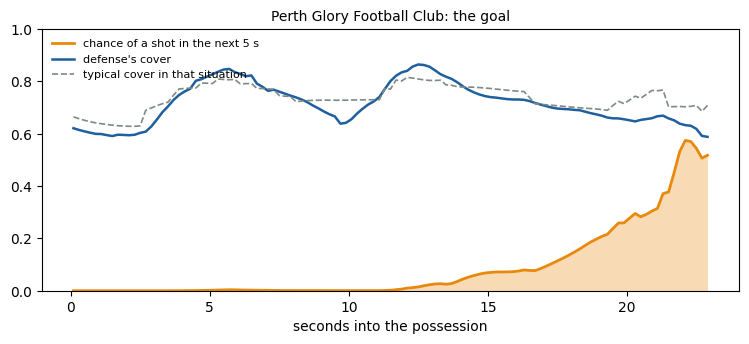

In [3]:
goal = possessions[possessions["goal"]].sort_values("duration_s").iloc[[-1]]
comparisons = T.Comparisons(values={"xg_here": xg.xg_from_here})
frames = T.match_threat(players, ball, goal, meta, vmax, comparisons=comparisons)
frames = DF.add_cover_columns(frames)
frames = frames[frames["frame"] <= goal["first_shot_frame"].iloc[0]].reset_index(drop=True)
frames["p_shot"] = DF.OPEN_DATA_TWO_PART.predict(frames)
frames["typical_cover"] = DF.OPEN_DATA_TYPICAL_COVER.predict(frames)
t = frames["t_in_possession"]

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.fill_between(t, 0, frames["p_shot"], color="#e8890c", alpha=0.3, lw=0)
ax.plot(t, frames["p_shot"], color="#e8890c", lw=2, label="chance of a shot in the next 5 s")
ax.plot(t, frames["cover_xg_here"], color="#1f5f9e", lw=1.8, label="defense's cover")
ax.plot(t, frames["typical_cover"], color="#7d8a83", ls="--", lw=1.2, label="typical cover in that situation")
ax.set_xlabel("seconds into the possession"); ax.set_ylim(0, 1)
ax.legend(frameon=False, fontsize=8, loc="upper left"); ax.set_title(f"{goal['team_id'].iloc[0] == meta.home_team_id and meta.home_name or meta.away_name}: the goal", fontsize=10)
plt.show()

As the attack nears the box the reachable danger rises, the defense's cover falls below what a typical defense would hold there, and the chance of a shot climbs. Cover and the ball's situation are kept as two separate inputs because multiplying them (Threat Conceded = reachable danger × uncovered share) forces them to carry equal weight. Fitted freely, the situation weighs about 2.3 times as much, and the product form failed our pre-declared test against ball distance.

## 3. Who holds the cover at the moment of greatest danger?

Pitch control sums over players, so the cover splits exactly across defenders: each defender's share is the part of the reachable shooting danger they would reach first. Below: the moment with the highest reachable danger, at least 2 s before the shot.

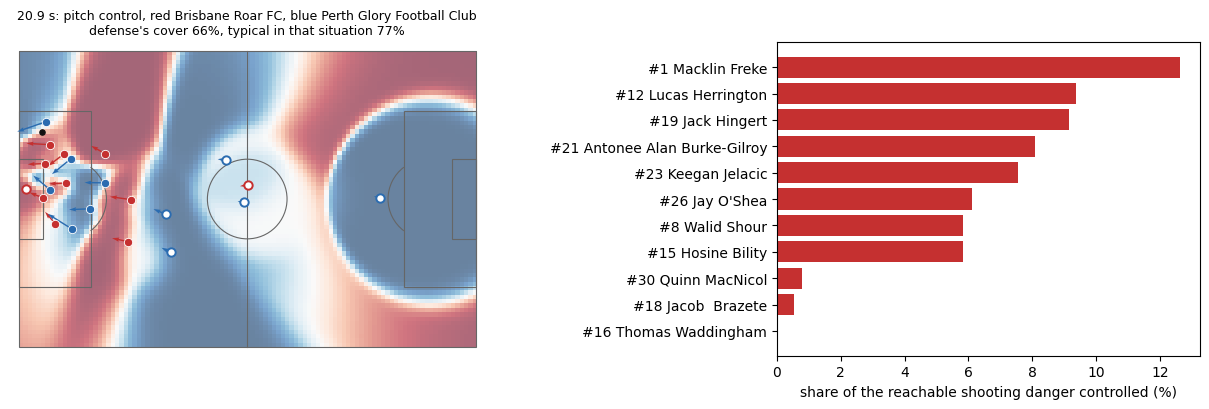

In [4]:
peak = frames[frames["t_in_possession"] <= t.max() - 2].sort_values("rd_xg_here").iloc[-1]
fx = T._Frames(players, ball, meta, vmax, PC.SKILLCORNER_OPEN_DATA)
state = fx.state(int(peak["frame"]))
attacking_home = bool(goal["attacking_home"].iloc[0])
grid = PC.make_grid(meta.pitch_length, meta.pitch_width, 2.0)
shares = A.defender_shares(state, attacking_home, grid, meta, T.ThreatModel(), {"xg_here": xg.xg_from_here})
shares["defender"] = shares["player_id"].map(lambda i: f"#{meta.players[i].number} {meta.players[i].name}")

pc = PC.pitch_control(state, PC.make_grid(meta.pitch_length, meta.pitch_width, 1.0), PC.SKILLCORNER_OPEN_DATA)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.5, 1]})
VZ.draw_pitch(axes[0], meta.pitch_length, meta.pitch_width)
VZ.plot_surface(axes[0], pc.grid, pc.team(True), cmap="RdBu_r", vmin=0, vmax=1, alpha=0.6)
VZ.plot_players(axes[0], state)
axes[0].set_title(f"{peak['t_in_possession']:.1f} s: pitch control, red {meta.home_name}, blue {meta.away_name}\n"
                  f"defense's cover {peak['cover_xg_here']:.0%}, typical in that situation {peak['typical_cover']:.0%}",
                  fontsize=9)
s = shares.sort_values("share_xg_here")
axes[1].barh(s["defender"], 100 * s["share_xg_here"], color=VZ.AWAY_C if attacking_home else VZ.HOME_C)
axes[1].set_xlabel("share of the reachable shooting danger controlled (%)")
plt.tight_layout(); plt.show()

## 4. Across the 20 matches

The full pipeline (`scripts/06`–`12`, about 2 hours) runs the same computation for every possession of the 20 matches. The main results, each in `reports/`:

- **Does cover predict shots beyond where the ball is?** Yes. Adding the defense's cover to a flexible model of the ball's situation improves held-out prediction (leave one match out) of a shot in the next 5 s and of the ball reaching the box, and, per possession, cover at the moment of greatest danger does too. Averaged over a possession, cover adds nothing ([w6_two_part.md](reports/w6_two_part.md)).
- **Why the first version failed.** The pre-declared test of Threat Conceded (the product) against ball distance failed ([w5_validation.md](reports/w5_validation.md)); the two-part model is the fix.
- **What a press does.** Every one of SkillCorner's 14,872 on-ball engagements is measured 3 s after the decision to press against typical play from the same situation, split into the effect on the ball and on the shape. The grade agrees with SkillCorner's own outcome flags: beaten presses cost about 13 shots per 100, presses that force the ball back save about 1.6 ([w7_pressing.md](reports/w7_pressing.md)).
- **What does not work yet.** Blaming the individual presser by their lost cover barely separates beaten presses from others, and players' pressing values are not stable within a position over 20 matches: individual skill needs more data ([w6_attribution.md](reports/w6_attribution.md)).

![cover effect](figs/w6_cover_effect.png)

![press value](figs/w7_press_value.png)

## 5. Explore it yourself

`py scripts/13_explorer.py` builds an interactive replay (`explorer/build/possession_explorer.html`) of five possessions: the open danger as a continuous field or summed into the 18 classic zones, the defense's cover against a typical defense, the chance of a shot, and each defender's share of the cover, five times a second. `py scripts/14_animate.py` writes the same replays as GIFs.

![a beaten press](figs/w8_beaten.gif)